# Clustering method

**Which algorithm makes the groups. K-means uses distance to centres; GMM models probability-based groups with different shapes.**

**First prerequisite:** prepare the account sample, then complete [01_baseline.ipynb](../01_baseline.ipynb). No historical experiment runs or original model checkpoints are used here.

**Work required:** Changed methods require clustering, diffusion, classifier training, and generation.

The generator's guidance classifiers predict parent groups. The separate overdraft evaluator stays fixed. You run this notebook yourself.

[Instructions and index](../../README.md) · [Final comparison](../02_all_experiments.ipynb) · [Research log](../../docs/PROGRESS.md)

In [6]:
import os
import sys
from pathlib import Path

import pandas as pd
import yaml
from IPython.display import Image
from IPython.display import display as show


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/transaction-evaluation-matplotlib")
MULTI_TABLE = ROOT / "implementations/tabular_data/multi_table"

from implementations.tabular_data.multi_table.evaluation.transaction_evaluation import evaluate_saved_runs
from implementations.tabular_data.multi_table.experiments.dataset_settings import DATA_DIR as DEFAULT_DATA_DIR
from implementations.tabular_data.multi_table.experiments.tuning import (
    DEFAULT_EXPERIMENT_ROOT,
    DEFAULT_REPORT_ROOT,
    PRESETS,
    base_config,
    completed_runs,
    make_trials,
    preview_trials,
    run_trials,
)


## 1. Settings — keep the baseline fixed

Use the `.venv` kernel. Start with one training/sampling seed and a short candidate list. Keep `RUN_NEW_TRIALS = False` to preview or evaluate completed results. Enable it yourself on a GPU to run a sweep.

The baseline parameter value is included automatically even if you narrow `VALUES`; duplicates are removed. All other settings match the baseline notebook. Keep its input data, root, full sample scale, and base settings fixed. Candidate values are starting experiments, not proven optimal choices.

In [7]:
EXPERIMENT = "clustering_method"
RUN_NEW_TRIALS = False
SAMPLING_SEEDS = [42]
TRAINING_SEEDS = [42, 43, 44]
# Edit dataset_settings.py once to switch every notebook, or override here.
DATA_DIR = DEFAULT_DATA_DIR
EXPERIMENT_ROOT = DEFAULT_EXPERIMENT_ROOT
OUTPUT_ROOT = DEFAULT_REPORT_ROOT
BASE = base_config(fresh_training=True)
PARAMETER, DEFAULT_VALUES = PRESETS[EXPERIMENT]
VALUES = list(DEFAULT_VALUES)  # Narrow this list for the first sweep.

print(f"Selected processed dataset: {DATA_DIR}")


Selected processed dataset: /home/armoso/repo/vector-bootcamp-synthetic-data/implementations/tabular_data/multi_table/data/berka_accounts_500_seed42


## 2. Preview and check the baseline

This creates no models or synthetic data. Stage IDs show logical reuse groups; completed stages are checked during execution. A model set covers all nine parent/table relations.

The baseline is included for each requested seed pair. Vary sampling seeds later to test generation variability; vary training seeds separately to test model variability.

In [8]:
TRIALS = make_trials(
    BASE, PARAMETER, VALUES, sampling_seeds=SAMPLING_SEEDS,
    training_seeds=TRAINING_SEEDS, include_baseline=True,
)
PLAN = preview_trials(TRIALS)
show(PLAN.drop(columns="config"))
COUNTS = PLAN[["cluster", "diffusion", "model", "sample"]].nunique()
print(f"Planned configurations/generations: {COUNTS['sample']} (includes the baseline).")
print(f"Logical sets before cache lookup: {COUNTS['cluster']} clustering, "
      f"{COUNTS['diffusion']} diffusion, {COUNTS['model']} classifier.")
BASELINE_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=[BASE]) if DATA_DIR.is_dir() else []
if BASELINE_DIRS:
    print("Baseline found. Matching completed stages will be reused.")
else:
    print("No completed baseline yet. Run 01_baseline.ipynb before enabling this sweep.")


,cluster,diffusion,model,sample,training_seed,sampling_seed,guidance,clusters
0,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,013d0db4bc897faae5dc,42,42,1.0,50
1,5bea0e858aeb21383d57,257d6f93959c99580ebb,d07d4ff6462dca3ca182,cb13efa4c1058b81651f,42,42,1.0,50
2,8bacd54a03e8e4f65b7c,189fda74c7e431d4f8d6,79586c7c0d46e23fea06,3a59a43a099de135703c,42,42,1.0,50
3,9bff39262da3114e3378,96e9747e34fe0dab855d,c7e37726fa93ff6db7fe,a1548bd6458955ff420a,43,42,1.0,50
4,fb5164a74188d7db48ec,54de163c6d3ae6578096,f2fa0b8f6d3fbad3b03d,35894b4410fcb27dcda6,43,42,1.0,50
5,7c05e1a33dc580546cca,d53609f754f76d8b8ba0,69915a1a9cb0b7b78afb,0e5694225e640ea7a157,43,42,1.0,50
6,8f89b1c222c3a39b687e,20bd03f27b55955b0fc4,f32b015badb3c8e25f3a,e418a2c6497aacdab373,44,42,1.0,50
7,c477952de128cd0eb553,71abacb790f6ff7b3389,dbe62ee39502ae18628a,bdada9e331f91e836629,44,42,1.0,50
8,27cac951054242d4559f,524ea150988413eb12a1,f8833bb6b506d2aca088,63546e2464457bf42a2d,44,42,1.0,50


Planned configurations/generations: 9 (includes the baseline).
Logical sets before cache lookup: 9 clustering, 9 diffusion, 9 classifier.
Baseline found. Matching completed stages will be reused.


## 3. Run this sweep on GPU

This step requires the completed baseline and your `RUN_NEW_TRIALS = True` setting. Compatible baseline stages are reused. Run one generating notebook at a time; retain the same experiment root across notebooks. Inspect `status.json` if a stage fails before choosing a fresh root to retry.

In [9]:
NEW_RUN_DIRS = []
if RUN_NEW_TRIALS:
    if not BASELINE_DIRS:
        raise ValueError("Create the reference run in 01_baseline.ipynb before starting this sweep.")
    EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
    PLAN.drop(columns="config").to_csv(EXPERIMENT_ROOT / f"plan_{EXPERIMENT}.csv", index=False)
    NEW_RUN_DIRS = run_trials(TRIALS, DATA_DIR, EXPERIMENT_ROOT, device="cuda")
    show(pd.DataFrame({"saved_run": [str(path) for path in NEW_RUN_DIRS]}))
else:
    print("Preview only. Enable RUN_NEW_TRIALS yourself after completing the baseline.")


Preview only. Enable RUN_NEW_TRIALS yourself after completing the baseline.


## 4. Evaluate completed results on CPU

A single real-trained overdraft detector evaluates the baseline and completed variants in this call. An early preview may show just the baseline; incomplete sweeps are not presented as complete comparisons.

Compare event counts, AP/prevalence/uncertainty, overall and overdraft-only distributions, account integrity, and chronology. A high raw synthetic AP alone does not establish the best data.

The same report also scores all 8 tables and 8 parent/child edges: column distributions, missing/unknown values, within/cross-table relationships, cardinalities, and PK/FK integrity. It checks client/account combinations through `disp`. The full-table and overdraft score groups remain separate; no combined winner score is used.

Evaluating 176a46c3cf813318e90e
Evaluating 17a666dff24de02c8b38
Evaluating 1dc8506a6e25e6ffffdd
Evaluating 524edfcd0e6f14a9c5b2
Evaluating 598ca51cf48e64e467a4
Evaluating 69d8d8e332567cece9b5
Evaluating ab83ca3baed8da78f64c
Evaluating e2cf71fc9b2cb2bdcc74
Evaluating fa627eaf5227b73e6be4


,parameter_value,average_precision,average_precision_low,average_precision_high,standardized_ap,overdraft_prevalence,transaction_ks,transaction_tvd,overdraft_numerical_ks,synthetic_transaction_before_account_rate
dataset,,,,,,,,,,
real_test,NaN,0.2422,0.0005,0.3606,0.2422,0.0017,NaN,NaN,NaN,NaN
176a46c3cf813318e90e,kmeans,0.0037,0.0026,0.0059,0.0031,0.0020,0.0506,0.0290,0.2353,0.1482
17a666dff24de02c8b38,gmm,0.0094,0.0081,0.0110,0.0043,0.0037,0.0673,0.0313,0.5938,0.2206
1dc8506a6e25e6ffffdd,gmm,0.0162,0.0147,0.0174,0.0055,0.0050,0.0514,0.0227,0.6890,0.2071
524edfcd0e6f14a9c5b2,kmeans_and_gmm,0.0063,0.0053,0.0076,0.0036,0.0029,0.0612,0.0281,0.4948,0.1606
598ca51cf48e64e467a4,gmm,0.0066,0.0056,0.0091,0.0034,0.0033,0.0528,0.0237,0.3882,0.1816
69d8d8e332567cece9b5,kmeans,0.0072,0.0061,0.0101,0.0037,0.0033,0.0535,0.0245,0.3938,0.1396
ab83ca3baed8da78f64c,kmeans,0.0148,0.0134,0.0168,0.0046,0.0054,0.0536,0.0234,0.6194,0.1634
e2cf71fc9b2cb2bdcc74,kmeans_and_gmm,0.0161,0.0144,0.0183,0.0056,0.0048,0.0560,0.0229,0.7073,0.2052


Detailed report: /home/armoso/repo/vector-bootcamp-synthetic-data/implementations/tabular_data/multi_table/results/experiments/transaction_overdraft_from_scratch/4a98a4d7b7ff8dde


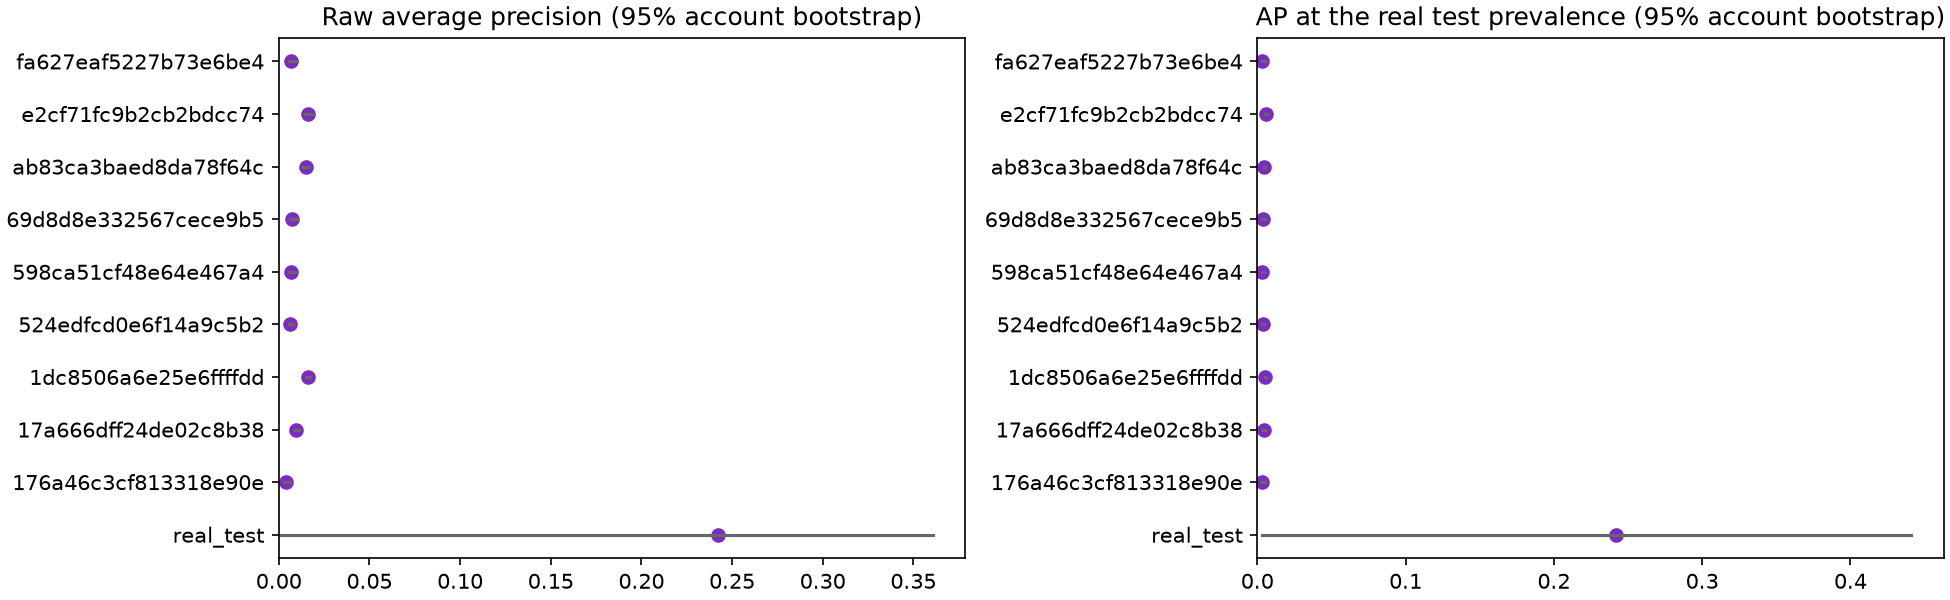

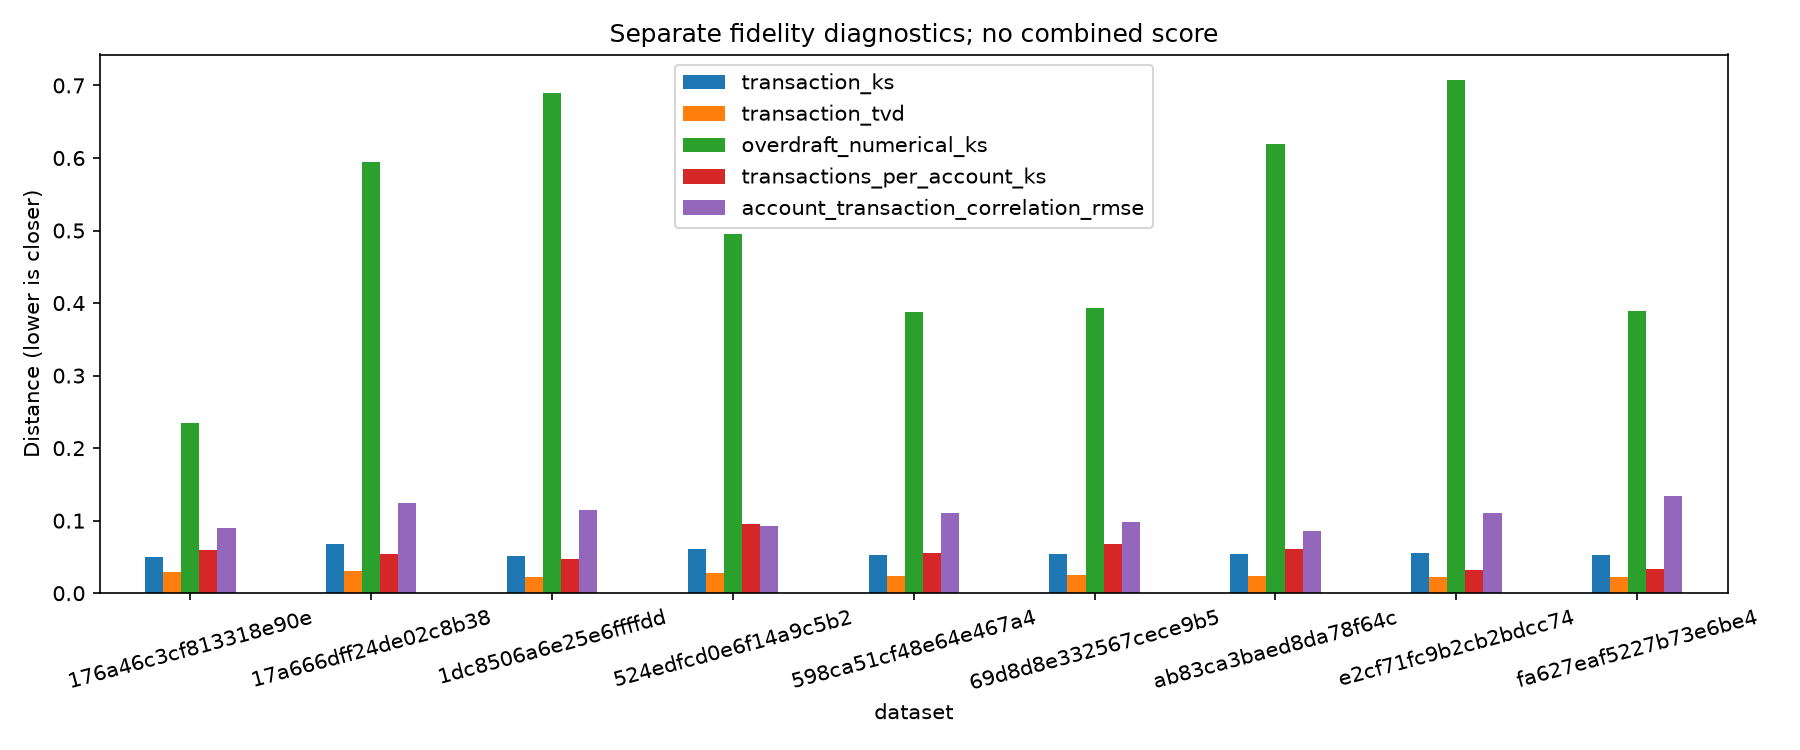

Completed 9 of 9 requested seed/configuration pairs.
Full multi-table quality — separate from overdraft transfer:


,all_table_count,all_edge_count,all_table_numerical_ks,all_table_categorical_tvd,all_cardinality_ks,all_relationship_correlation_rmse,all_min_fk_valid_rate,all_min_pk_unique_rate,multi_parent_correlation_rmse,multi_parent_joint_categorical_tvd,all_undefined_distribution_columns,all_undefined_correlation_pairs
dataset,,,,,,,,,,,,
176a46c3cf813318e90e,8.0,8.0,0.0999,0.1030,0.0537,NaN,0.9857,1.0,0.0127,0.1647,0.0,2.0
17a666dff24de02c8b38,8.0,8.0,0.1075,0.0964,0.0783,NaN,0.8734,1.0,0.0095,0.1634,0.0,2.0
1dc8506a6e25e6ffffdd,8.0,8.0,0.0832,0.0998,0.0757,NaN,1.0000,1.0,0.0087,0.1543,0.0,2.0
524edfcd0e6f14a9c5b2,8.0,8.0,0.0999,0.0984,0.0561,NaN,1.0000,1.0,0.0230,0.1598,0.0,2.0
598ca51cf48e64e467a4,8.0,8.0,0.0961,0.1015,0.0863,NaN,0.7500,1.0,0.0130,0.1550,0.0,2.0
69d8d8e332567cece9b5,8.0,8.0,0.1122,0.1164,0.1333,NaN,0.6754,1.0,0.0325,0.1785,0.0,2.0
ab83ca3baed8da78f64c,8.0,8.0,0.0802,0.0951,0.0566,NaN,0.9451,1.0,0.0141,0.1479,0.0,2.0
e2cf71fc9b2cb2bdcc74,8.0,8.0,0.1110,0.1111,0.0867,NaN,1.0000,1.0,0.0445,0.1888,0.0,2.0
fa627eaf5227b73e6be4,8.0,8.0,0.1071,0.1200,0.0680,NaN,0.8514,1.0,0.0215,0.1638,0.0,2.0


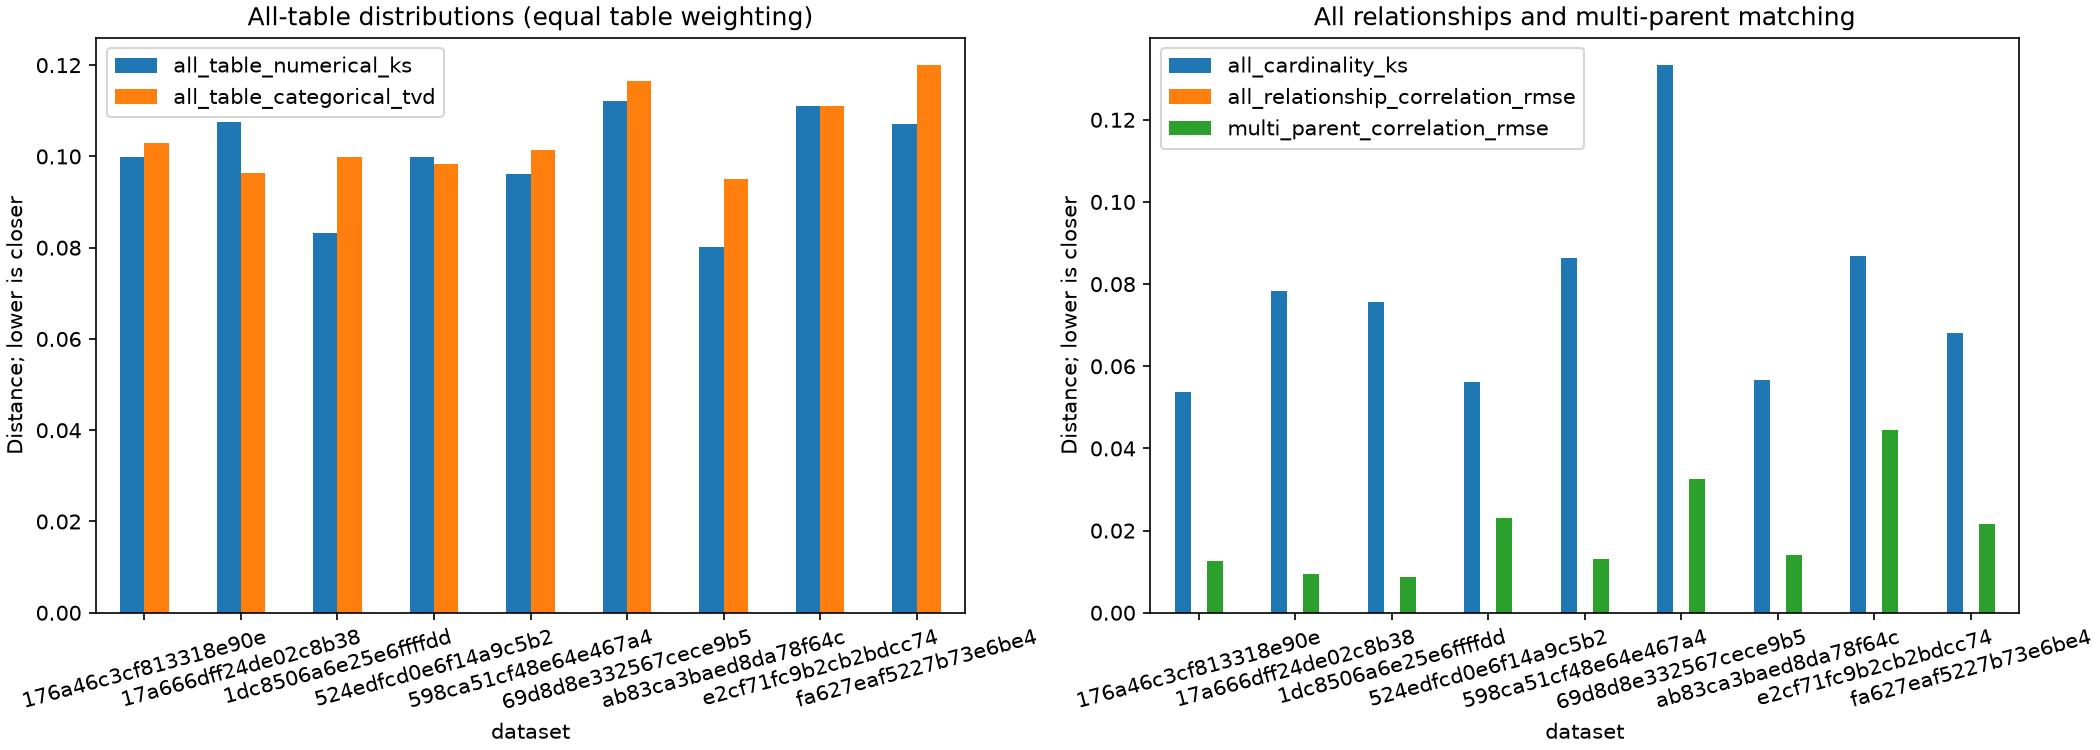

In [10]:
RUN_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=TRIALS) if DATA_DIR.is_dir() else []
comparison = None
REPORT_DIR = None
if RUN_DIRS:
    comparison, REPORT_DIR = evaluate_saved_runs(DATA_DIR, RUN_DIRS, OUTPUT_ROOT, bootstrap_repetitions=200)
    section, field = PARAMETER.split(".")
    parameter_values = {}
    for run in RUN_DIRS:
        saved = yaml.safe_load((run / "config.yaml").read_text())
        parameter_values[run.name] = str(saved[section][field])
    comparison.insert(0, "parameter_value", pd.Series(parameter_values))
    TRANSFER_AND_QUALITY = [
        "average_precision", "average_precision_low", "average_precision_high",
        "standardized_ap", "overdraft_prevalence", "transaction_ks", "transaction_tvd",
        "overdraft_numerical_ks", "synthetic_transaction_before_account_rate",
    ]
    show(comparison[["parameter_value", *TRANSFER_AND_QUALITY]].round(4))
    print(f"Detailed report: {REPORT_DIR}")
    show(Image(filename=str(REPORT_DIR / "transfer_intervals.png")))
    show(Image(filename=str(REPORT_DIR / "quality_comparison.png")))
    print(f"Completed {len(RUN_DIRS)} of {len(TRIALS)} requested seed/configuration pairs.")
else:
    print("No completed results for this experiment. Start with 01_baseline.ipynb.")

if comparison is not None:
    FULL_TABLE_COLUMNS = [
        "all_table_count", "all_edge_count", "all_table_numerical_ks", "all_table_categorical_tvd",
        "all_cardinality_ks", "all_relationship_correlation_rmse", "all_min_fk_valid_rate",
        "all_min_pk_unique_rate", "multi_parent_correlation_rmse", "multi_parent_joint_categorical_tvd",
        "all_undefined_distribution_columns", "all_undefined_correlation_pairs",
    ]
    print("Full multi-table quality — separate from overdraft transfer:")
    show(comparison.loc[comparison.index != "real_test", FULL_TABLE_COLUMNS].round(4))
    show(Image(filename=str(REPORT_DIR / "multi_table_quality.png")))


## 5. Conclusion — clustering method (2026-11-12)

**Decision: keep `kmeans_and_gmm`. `kmeans` is the only setting with a repeatable chronology gain: fewer transactions before account opening in every seed tested. It costs transfer and does not fix chronology. Revisit it after the date fix.**

**Two checks were run:**
- **Sampling-seed check:** training seed 42 × sampling seeds 42/43/44. This varies generation only. ([report](../../../results/experiments/transaction_overdraft_from_scratch/17381feb1e1e40ef/comparison.csv))
- **Training-seed check:** training seeds 42/43/44 × sampling seed 42. This retrains every model per seed. ([report](../../../results/experiments/transaction_overdraft_from_scratch/4a98a4d7b7ff8dde/comparison.csv))

### Sampling-seed check (mean ± sd over sampling seeds)

| Method | Standardized AP ↑ | ROC-AUC ↑ | Transactions (real 117,560) | All-table numerical KS ↓ | Before opening ↓ |
| --- | ---: | ---: | ---: | ---: | ---: |
| `gmm` | 0.0054 ± 0.0001 | 0.772 ± 0.002 | 126,976 | 0.089 ± 0.006 | 19.4% ± 2.2 |
| `kmeans` | 0.0048 ± 0.0002 | 0.743 ± 0.013 | 101,009 | 0.092 ± 0.014 | 15.3% ± 1.2 |
| **`kmeans_and_gmm` (baseline)** | 0.0054 ± 0.0003 | 0.763 ± 0.007 | 114,050 | 0.104 ± 0.012 | 18.9% ± 1.8 |

### Training-seed check (seed 42 / 43 / 44)

| Method | ROC-AUC ↑ | Standardized AP ↑ | Categorical TVD ↓ | Account→trans corr. RMSE ↓ | Before opening ↓ | Accounts ever overdrawn | Orphan cards |
| --- | --- | --- | --- | --- | --- | --- | --- |
| `gmm` | 0.774 / 0.630 / 0.704 | 0.0055 / 0.0034 / 0.0043 | 0.100 / 0.102 / 0.096 | 0.115 / 0.110 / 0.124 | 20.7 / 18.2 / 22.1% | 64.3 / 49.2 / 54.9% | 0 / 28 / 10 |
| `kmeans` | 0.730 / 0.621 / 0.552 | 0.0046 / 0.0037 / 0.0031 | 0.095 / 0.116 / 0.103 | 0.086 / 0.098 / 0.090 | 16.3 / 14.0 / 14.8% | 65.3 / 50.9 / 34.4% | 5 / 37 / 1 |
| **`kmeans_and_gmm` (baseline)** | 0.769 / 0.614 / 0.653 | 0.0056 / 0.0034 / 0.0036 | 0.111 / 0.120 / 0.098 | 0.110 / 0.134 / 0.093 | 20.5 / 23.1 / 16.1% | 58.1 / 51.8 / 43.9% | 0 / 11 / 0 |

**Real reference:** test AP 0.2422, ROC-AUC 0.8722; 5.6% of accounts ever overdrawn; 0% of transactions before opening.

- **`kmeans` has fewer pre-opening transactions than the baseline in all 5 seed pairs tested.** It also has better account→transaction correlation in every training seed. However, ROC-AUC is lower in 2 of 3 training seeds (mean 0.634 vs 0.679), and about 15% of transactions before opening is still far from 0%.
- **`gmm` has a small edge on ROC-AUC and categorical TVD in every training seed.** The ROC-AUC gain is +0.005, +0.016 and +0.051, which is small next to the baseline's retraining sd of 0.081. It also had more orphan cards (28 and 10) and more overdrawn accounts in 2 of 3 seeds.
- **Retraining dominates.** Baseline ROC-AUC spans 0.614–0.769 across training seeds, versus ±0.007 across sampling seeds.
- **Every method produced orphan cards, including the baseline (11 at seed 43).** The cause is a multi-parent matching bug, not the clustering method; see [PROGRESS.md](../../docs/PROGRESS.md).
- **No method fixes** overdraft concentration (34–65% vs real 5.6%).

**Next:** after the orphan-card and date-representation fixes, compare `kmeans` with the baseline over 3 training seeds, paired by seed.